In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn import linear_model,metrics,preprocessing

In [2]:
train=np.loadtxt("q5_train.csv",skiprows=1,delimiter=",")
test=np.loadtxt("q5_test.csv",skiprows=1,delimiter=",")
X_train, y_train = train[:, :-1], train[:, -1]
X_test, y_test= test[:, :-1], test[:, -1]

In [3]:
std=preprocessing.RobustScaler()
std.fit(X_train)
std_X_train=std.transform(X_train)
std_X_test=std.transform(X_test)

x = std_X_train[:, 7]
median = np.median(x)
mad = np.median(np.abs(x - median))
mask = np.abs(x - median) <= 3 * mad

X_train_clean = std_X_train[mask]
y_train_clean = y_train[mask]
train_clean = train[mask]

print(X_train_clean.shape, X_train.shape)

(113, 8) (120, 8)


# Corr Coeff

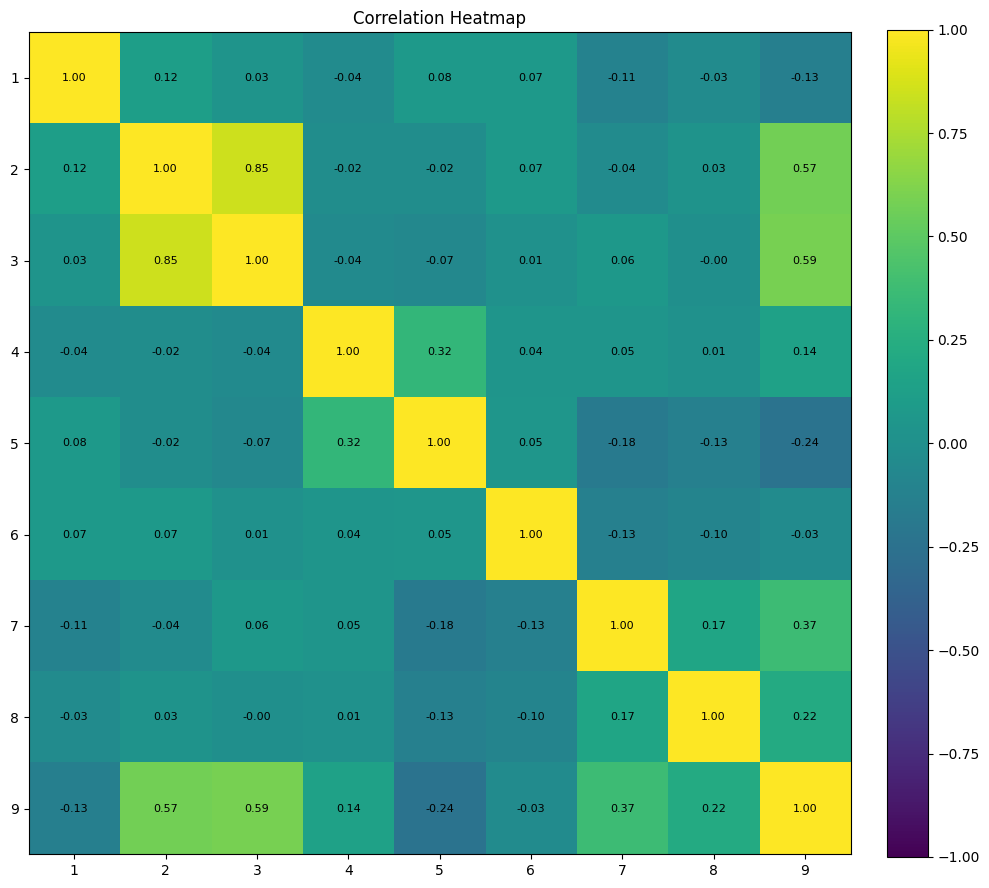

In [4]:
corr = np.corrcoef(train_clean, rowvar=False)

n = corr.shape[0]
labels = np.arange(1, n + 1)

plt.figure(figsize=(10, 10))
im = plt.imshow(corr, vmin=-1, vmax=1)

plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(np.arange(n), labels)
plt.yticks(np.arange(n), labels)

# annotate values
for i in range(n):
    for j in range(n):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Scatter plot

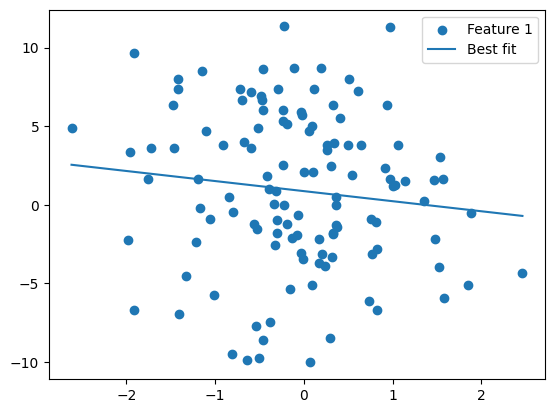

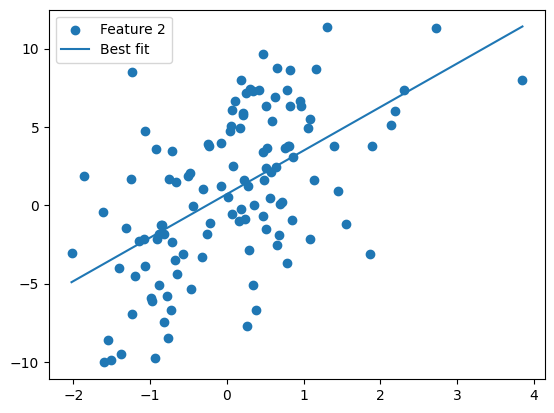

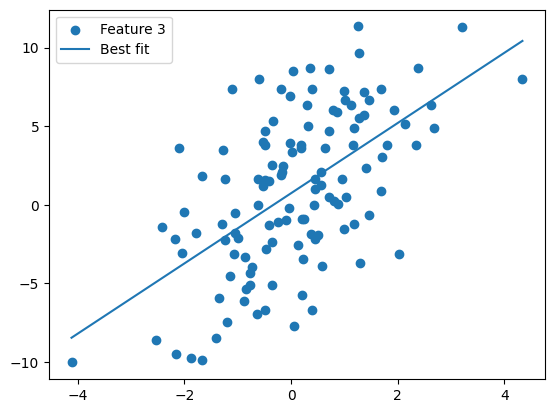

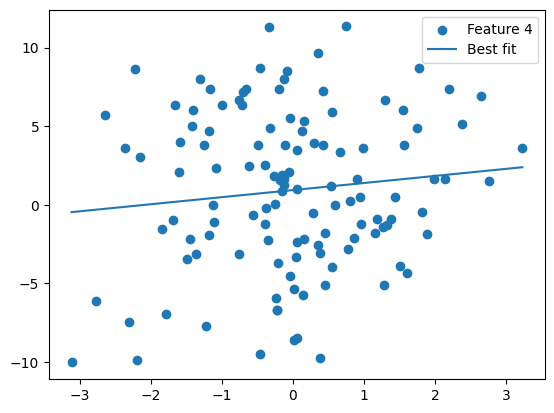

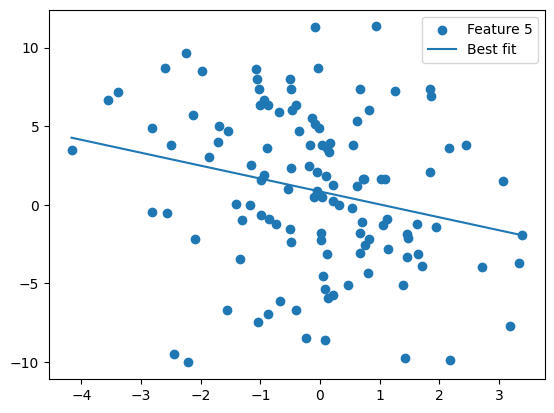

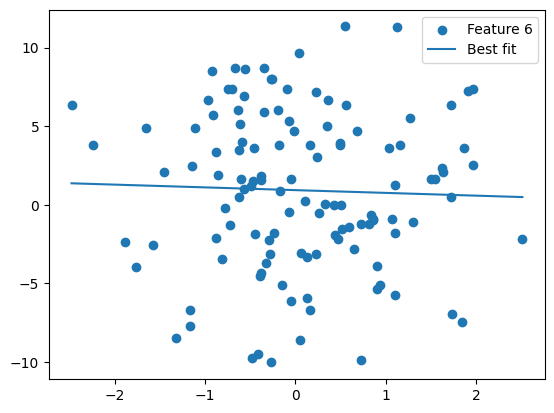

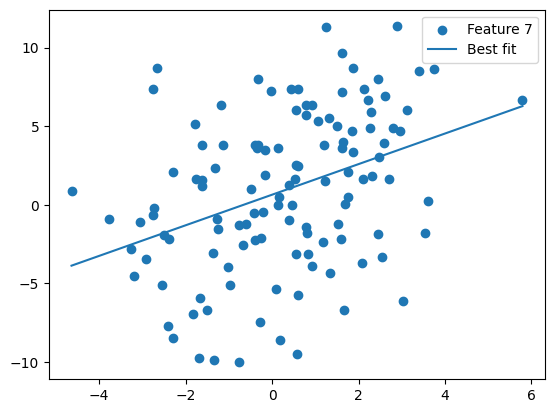

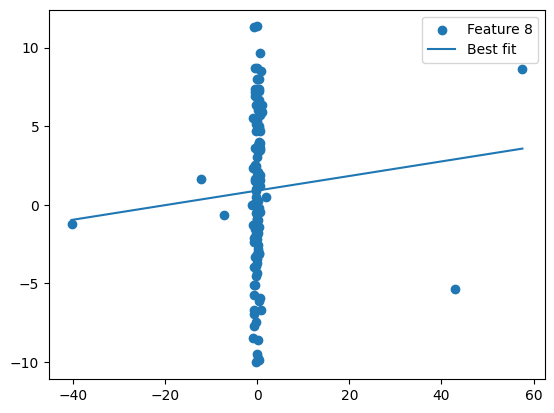

In [5]:
for i in range(X_train.shape[1]):
    x = X_train[:, i]
    plt.figure()
    plt.scatter(x, y_train, label=f'Feature {i+1}')
    plt.plot(np.sort(x), np.polyval(np.polyfit(x, y_train, 1), np.sort(x)), label='Best fit')
    plt.legend()
    plt.show()

# Normal

[-0.53050101  1.90111611  0.92090278  0.84520188 -0.72493984 -0.02067353
  0.8199396   0.04904944]
8


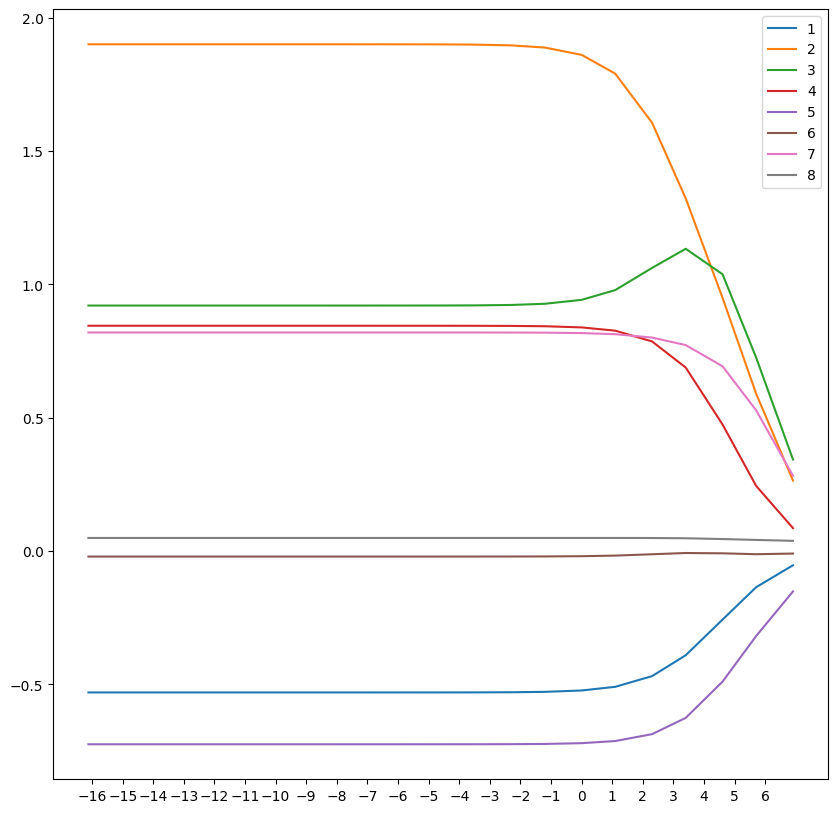

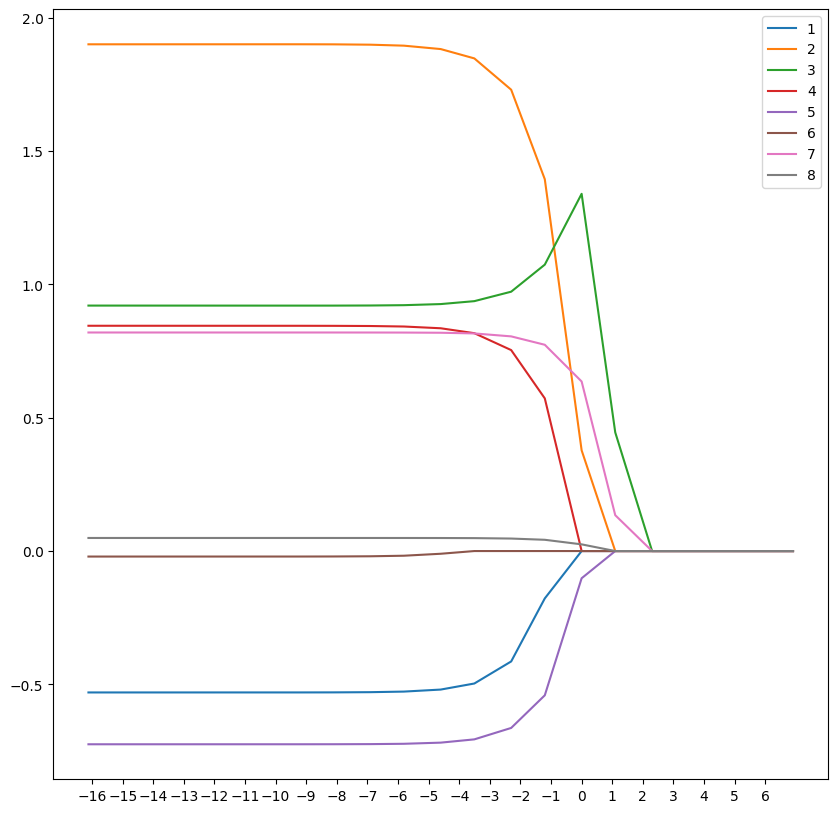

In [6]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(X_train,y_train)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(X_train,y_train)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(X_train,y_train)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


# Standardised

[-0.50644892  2.70114963  1.57100584  1.275197   -1.27291925 -0.02704547
  2.34580761  0.03376743]
8


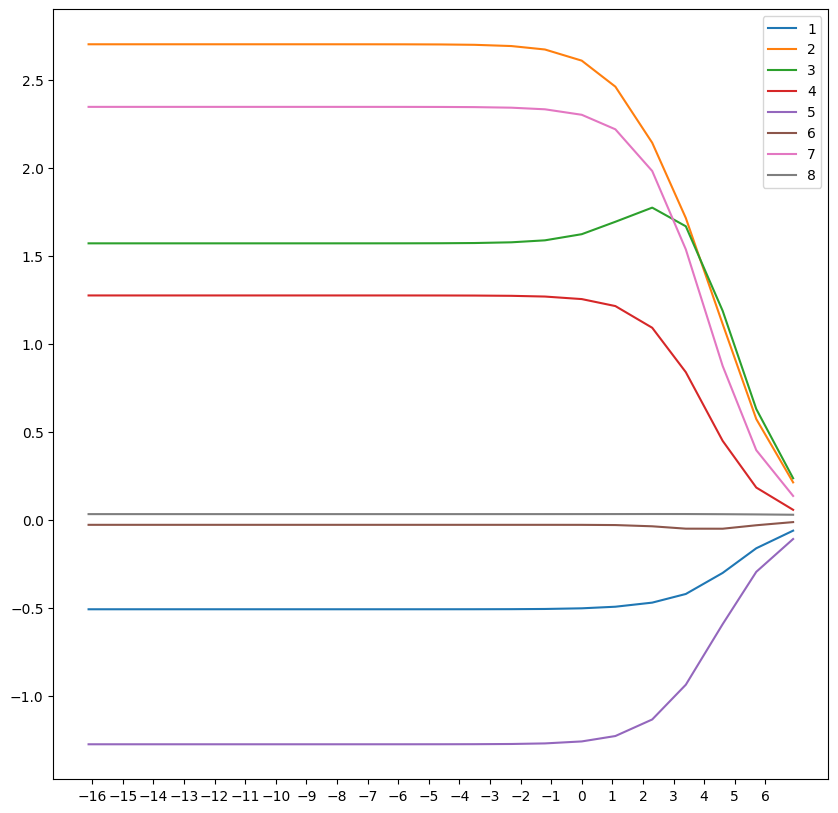

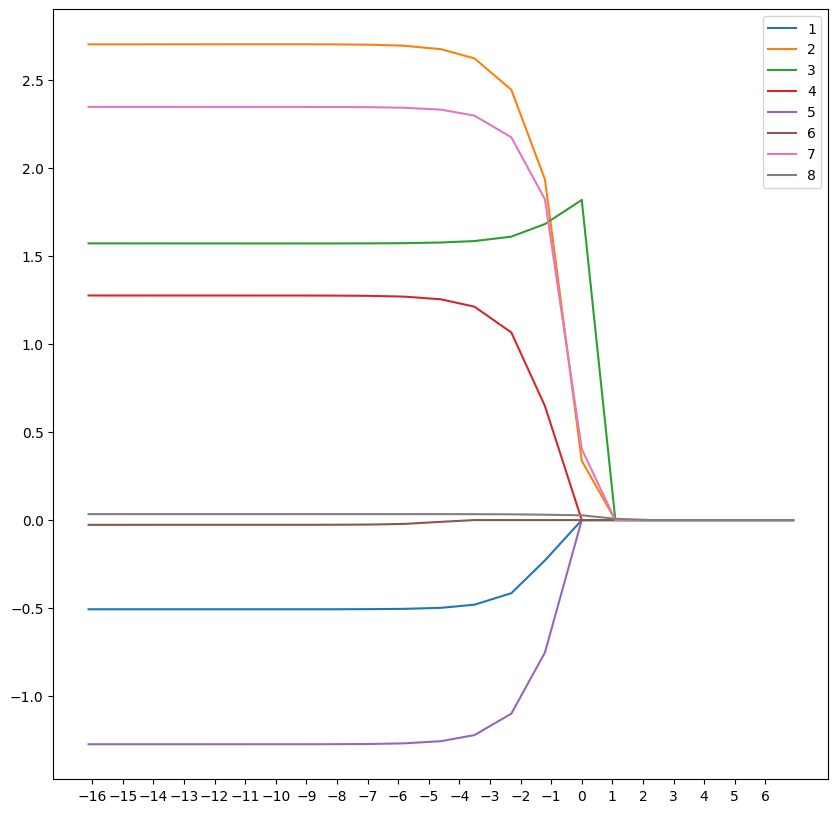

In [7]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(std_X_train,y_train)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(std_X_train,y_train)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(std_X_train,y_train)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


# Outliers Removed (after standardising)

[-0.66543444  2.71791732  1.61474317  1.25899528 -1.18044657 -0.01938702
  2.17804434  1.01507285]
8


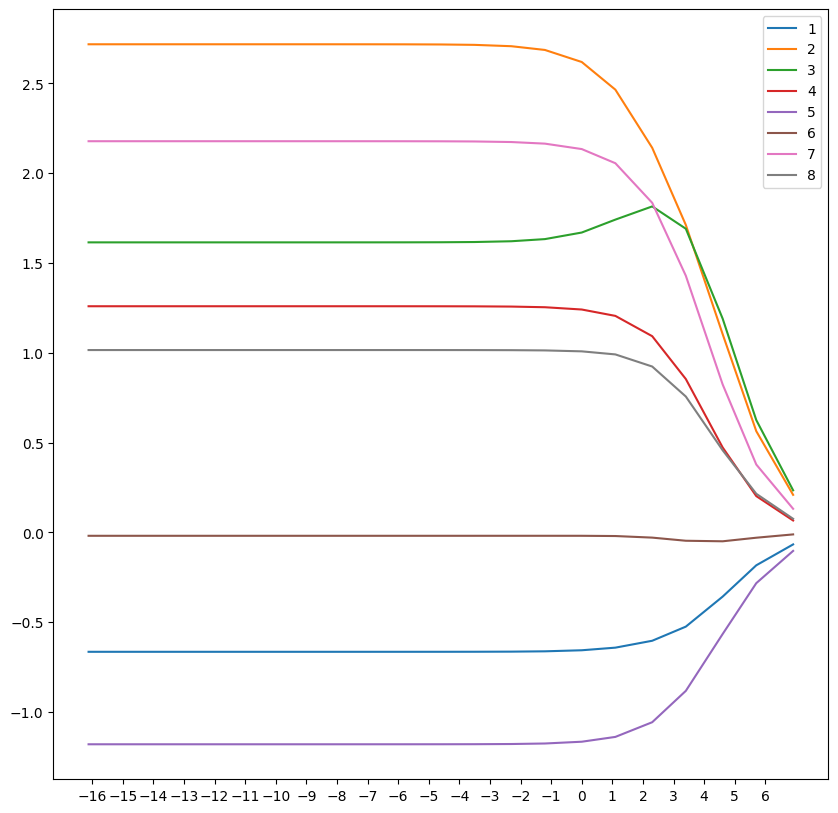

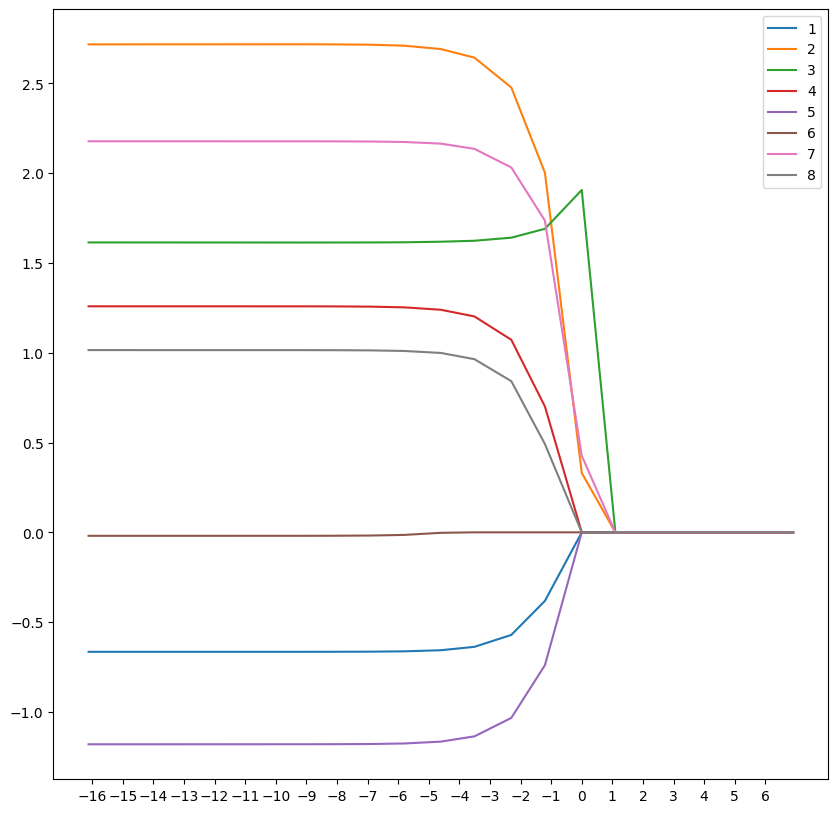

In [8]:
alphas = [1e-7, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1, 3, 10, 30, 100, 300, 1000]
log_al=np.log(np.array(alphas))
reg=linear_model.LinearRegression()
reg.fit(X_train_clean,y_train_clean)
print(reg.coef_)

features=reg.coef_.size
print(features)
coeffs=[]
for i in alphas:
    ridge=linear_model.Ridge(alpha=i)
    ridge.fit(X_train_clean,y_train_clean)
    coeffs.append(ridge.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()

coeffs=[]
for i in alphas:
    lasso=linear_model.Lasso(alpha=i)
    lasso.fit(X_train_clean,y_train_clean)
    coeffs.append(lasso.coef_)

coeffs=np.array(coeffs)

plt.figure(figsize=(10,10))
for i in range(features):
    plt.plot(log_al,coeffs[:,i],label=i+1)
plt.xticks(np.arange(int(log_al.min()), int(log_al.max()) + 1))
plt.legend()
plt.show()


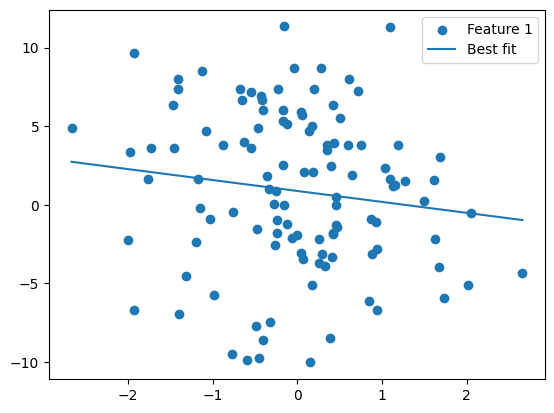

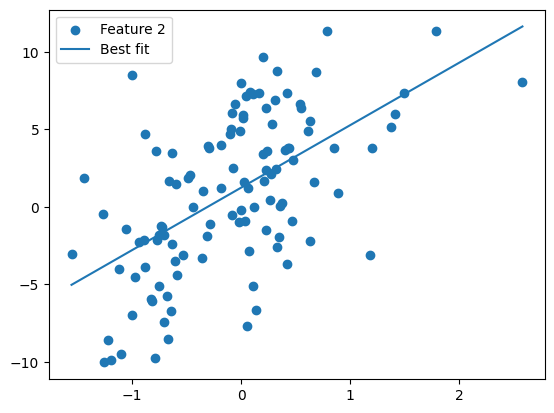

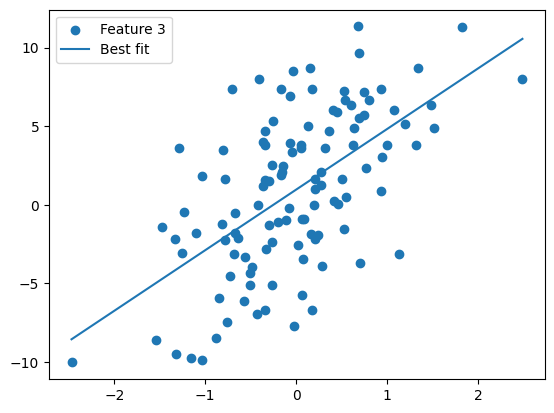

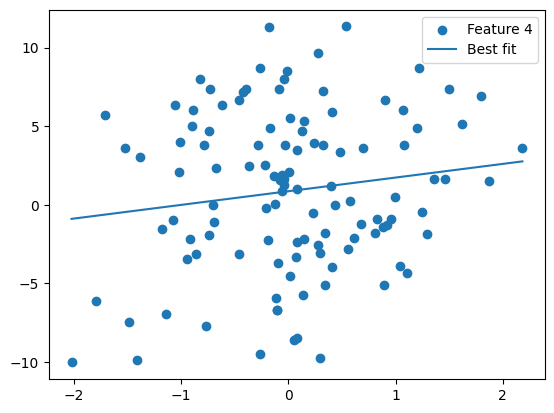

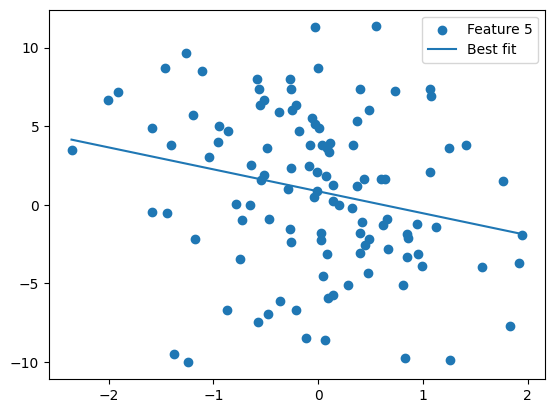

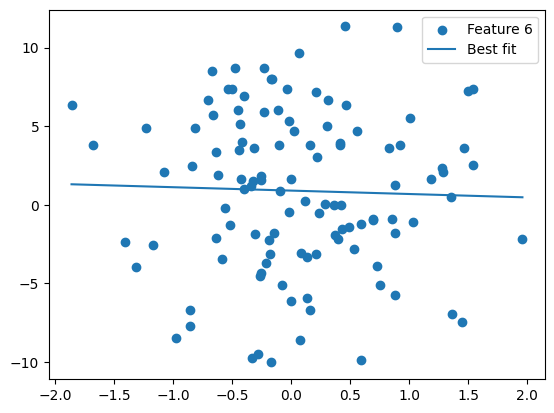

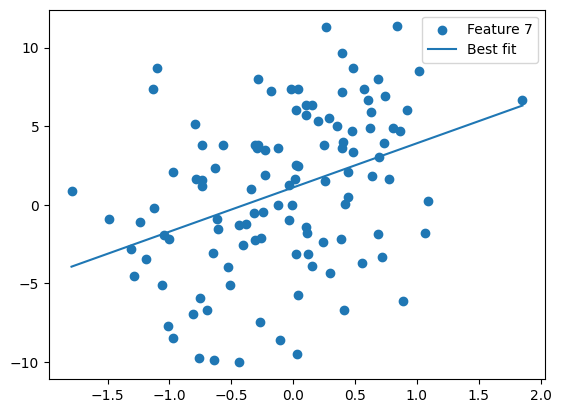

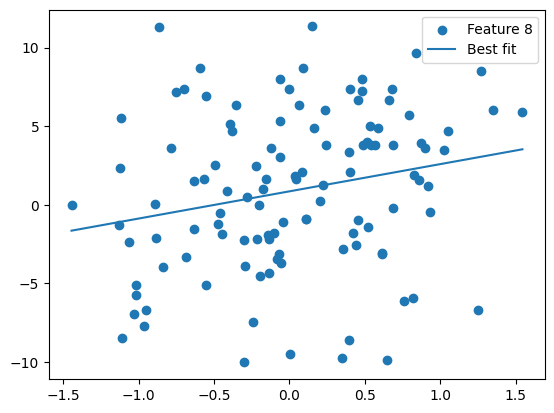

In [9]:
for i in range(X_train_clean.shape[1]):
    x = X_train_clean[:, i]
    plt.figure()
    plt.scatter(x, y_train_clean, label=f'Feature {i+1}')
    plt.plot(np.sort(x), np.polyval(np.polyfit(x, y_train_clean, 1), np.sort(x)), label='Best fit')
    plt.legend()
    plt.show()